# Notebook 07: So sánh Tiêu chí Liên kết và Chọn Số Cụm Tối ưu K*

- **Mục tiêu:**
  - Quyết định 7: Chọn tiêu chí liên kết (Single, Complete, Average, Ward).
  - Quyết định 8: Xác định số cụm tối ưu $K^*$ trong bài toán gom nhóm cổ phiếu VN100.
- **Dữ liệu:** Tập Train 2022–2024 (98 mã $\times$ 739 phiên). Khoảng cách Mantegna $d(i,j) = \sqrt{2(1 - \rho_{ij})}$.
- **Mô hình:** Hierarchical Bottom-Up (đã chọn ở Notebook 06); đối chứng với Baseline K-Means.

### Các bước thực nghiệm:
1. **Vòng 1 (Hình thái cây & CCC):** Vẽ Dendrogram 4 linkage, đo hệ số tương quan Cophenetic (CCC).
2. **Vòng 2 (Quét $K \in [3, 15]$):** Đo Silhouette, entropy kích thước cụm, kiểm tra cụm đơn lẻ (singleton) và độ phân tách tương quan $\Delta = \bar{\rho}_{\text{intra}} - \bar{\rho}_{\text{inter}}$.
3. **Vòng 3 (Baseline & Đánh giá cụm):**
   - So sánh với K-Means (PCA 5D và PCA 45D giữ 80% phương sai).
   - Kiểm định độ ổn định qua Block Sub-sampling ($B=30$, lấy mẫu 80% số phiên).
   - Phân tích 10 cụm ngành và rà soát các mã cổ phiếu ở vùng ranh giới.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import squareform, pdist
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(".").resolve()

TRAIN_DIR = PROJECT_ROOT / "data" / "processed" / "train"
META_PATH = PROJECT_ROOT / "data" / "metadata" / "vn100_symbols.csv"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
REPORT_IMG_DIR = PROJECT_ROOT / "docs" / "report" / "images"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_IMG_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "Times New Roman"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 150

# Nạp dữ liệu tập Train (cô lập hoàn toàn với tập Test)
train_returns = pd.read_csv(TRAIN_DIR / "train_log_returns.csv", index_col=0)
train_corr = pd.read_csv(TRAIN_DIR / "train_correlation_matrix.csv", index_col=0)
train_dist = pd.read_csv(TRAIN_DIR / "train_mantegna_distance_matrix.csv", index_col=0)
meta_df = pd.read_csv(META_PATH)

symbols = train_dist.columns.tolist()
N = len(symbols)
T_train = len(train_returns)

X_returns = train_returns.T.values          # (98, 739)
corr_mat = train_corr.loc[symbols, symbols].values
dist_mat = train_dist.loc[symbols, symbols].values
np.fill_diagonal(dist_mat, 0.0)
dist_mat = 0.5 * (dist_mat + dist_mat.T)    # Bảo đảm đối xứng tuyệt đối
D_condensed = squareform(dist_mat, checks=True)

# Kiểm chứng đẳng thức hình học Mantegna <-> Euclid trên mặt cầu đơn vị S^(T-1)
Z_norm = (X_returns - X_returns.mean(axis=1, keepdims=True))
Z_unit = Z_norm / np.linalg.norm(Z_norm, axis=1, keepdims=True)
D_euclid_unit = pdist(Z_unit, metric="euclidean")
max_geom_diff = np.max(np.abs(D_condensed - D_euclid_unit))

print(f"Số cổ phiếu (N): {N} | Số phiên Train (T): {T_train} (Q = T/N = {T_train / N:.2f} >> 1)")
print(f"Số ô khuyết thiếu trong ma trận khoảng cách: {np.isnan(dist_mat).sum()}")
print(f"Sai số hình học tối đa |d_Mantegna - d_Euclid(S^(T-1))|: {max_geom_diff:.2e}")

Số cổ phiếu (N): 98 | Số phiên Train (T): 739 (Q = T/N = 7.54 >> 1)
Số ô khuyết thiếu trong ma trận khoảng cách: 0
Sai số hình học tối đa |d_Mantegna - d_Euclid(S^(T-1))|: 3.77e-15


### Kiểm tra dữ liệu và cơ sở dùng Ward Linkage
- Dữ liệu Train gồm 98 cổ phiếu trong 739 phiên, không có giá trị thiếu. Tỷ số $T/N = 7.54 > 1$ đủ lớn để ma trận tương quan ổn định.
- **Tính hợp lệ của Ward Linkage trên khoảng cách Mantegna:**
  - Về mặt lý thuyết, Ward yêu cầu khoảng cách Euclid.
  - Khi vector lợi suất được chuẩn hóa (z-score chia $\sqrt{T}$), khoảng cách Euclid giữa hai chuỗi chính bằng khoảng cách Mantegna: $d(i,j) = \sqrt{2(1 - \rho_{ij})}$.
  - Sai số số học tối đa đo được trên dữ liệu thực tế là $3.77 \times 10^{-15}$ (bằng 0 trên độ chính xác dấu phẩy động). Do đó, áp dụng Ward trực tiếp lên ma trận Mantegna là hoàn toàn chuẩn xác.

VÒNG 1: HỆ SỐ BẢO TOÀN KHOẢNG CÁCH GỐC (COPHENETIC CORRELATION - CCC)
  - Single Linkage (Khoảng cách nhỏ nhất)         | CCC = 0.8664
  - Complete Linkage (Khoảng cách lớn nhất)       | CCC = 0.6760
  - Average Linkage (UPGMA)                       | CCC = 0.9046
  - Ward Linkage (Tối thiểu phương sai WSS)       | CCC = 0.3615


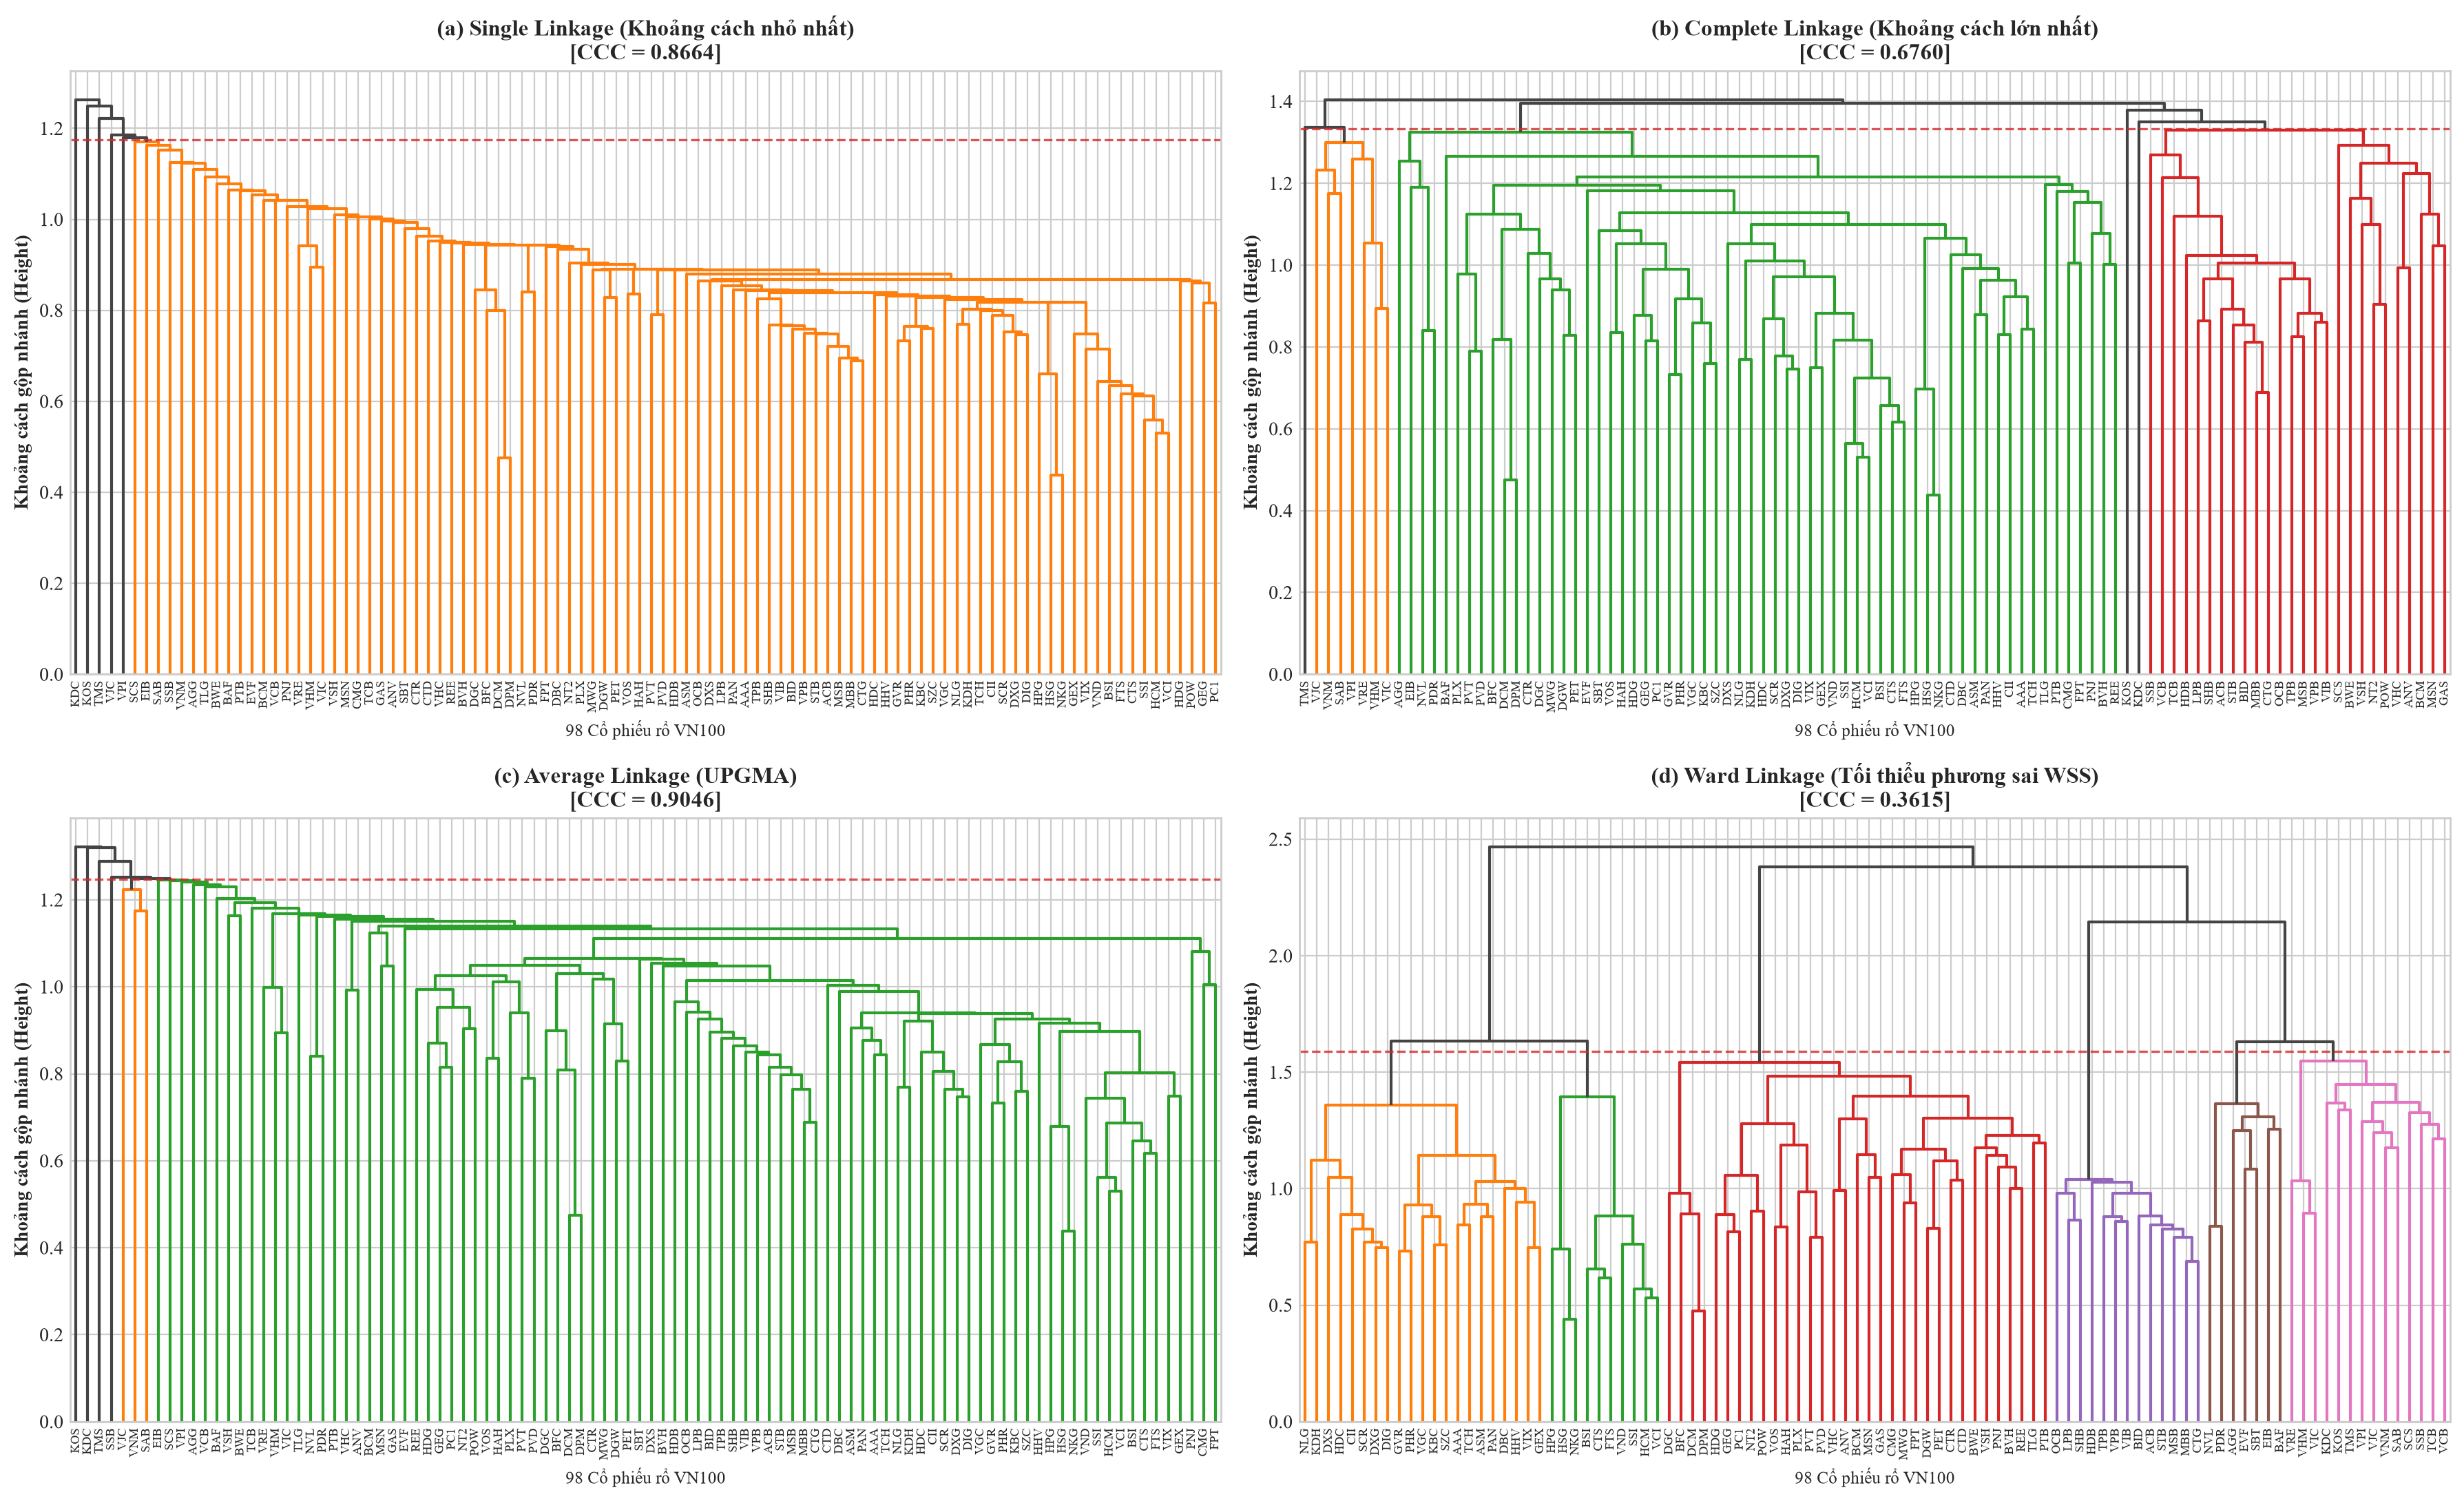

Đã lưu biểu đồ Dendrogram tại: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\reports\figures\07_dendrograms_4_linkages.png


In [2]:
LINKAGES = ["single", "complete", "average", "ward"]
LINKAGE_TITLES = {
    "single": "Single Linkage (Khoảng cách nhỏ nhất)",
    "complete": "Complete Linkage (Khoảng cách lớn nhất)",
    "average": "Average Linkage (UPGMA)",
    "ward": "Ward Linkage (Tối thiểu phương sai WSS)"
}

Z_dict = {}
ccc_dict = {}

print("=" * 68)
print("VÒNG 1: HỆ SỐ BẢO TOÀN KHOẢNG CÁCH GỐC (COPHENETIC CORRELATION - CCC)")
print("=" * 68)
for m in LINKAGES:
    Z_m = linkage(D_condensed, method=m)
    ccc_val, _ = cophenet(Z_m, D_condensed)
    Z_dict[m] = Z_m
    ccc_dict[m] = float(ccc_val)
    print(f"  - {LINKAGE_TITLES[m]:<45} | CCC = {ccc_val:.4f}")
print("=" * 68)

# Vẽ lưới 2x2 Cây phả hệ Dendrogram cho 4 tiêu chí liên kết
fig, axes = plt.subplots(2, 2, figsize=(18, 11), dpi=200)
axes = axes.flatten()

for idx, m in enumerate(LINKAGES):
    ax = axes[idx]
    Z_m = Z_dict[m]
    # Đặt ngưỡng tô màu tham chiếu tại lát cắt tương ứng 6 nhánh lớn
    color_thresh = 0.5 * (Z_m[-6, 2] + Z_m[-5, 2])
    dendrogram(
        Z_m,
        labels=symbols,
        ax=ax,
        leaf_rotation=90,
        leaf_font_size=6.5,
        color_threshold=color_thresh,
        above_threshold_color="#444444"
    )
    ax.axhline(color_thresh, color="#d62728", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.set_title(f"({chr(97+idx)}) {LINKAGE_TITLES[m]}\n[CCC = {ccc_dict[m]:.4f}]", fontsize=12, fontweight="bold")
    ax.set_ylabel("Khoảng cách gộp nhánh (Height)", fontsize=10, fontweight="bold")
    ax.set_xlabel("98 Cổ phiếu rổ VN100", fontsize=9)

plt.tight_layout()
fig_dendro = FIG_DIR / "07_dendrograms_4_linkages.png"
plt.savefig(fig_dendro, dpi=300, bbox_inches="tight")
plt.savefig(REPORT_IMG_DIR / "hinh_dendrogram_4_linkages.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ Dendrogram tại: {fig_dendro}")

### Vòng 1: Đánh giá hình thái cây và Hệ số Cophenetic (CCC)
- **Average ($CCC = 0.9046$) và Single ($CCC = 0.8664$):** Có CCC cao nhất do bảo toàn khoảng cách trung bình và tối thiểu khi gộp cụm. Tuy nhiên, dendrogram cho thấy cả hai đều bị hiệu ứng xâu chuỗi (chaining effect): phần lớn cổ phiếu dồn vào một nhánh lớn, chỉ có vài mã ngoại lai tách riêng.
- **Complete ($CCC = 0.6760$):** Cây cân đối hơn Single nhưng vẫn còn một số nhánh dồn mã.
- **Ward ($CCC = 0.3615$):** CCC thấp hơn vì Ward tối thiểu hóa phương sai nội cụm ($\Delta WSS$) thay vì bảo toàn khoảng cách tuyến tính ban đầu. Bù lại, dendrogram của Ward chia nhánh đồng đều, tạo thành các cụm có quy mô cân bằng và dễ phân tách thành các nhóm ngành.

TOP SILHOUETTE MỖI LINKAGE (BAO GỒM CẢ BẪY SINGLETON):
  - Single   : K=3  | Sil=0.1486 | Delta=+0.2521 | Singletons=2 | MaxShare=98.0% | Sizes=[96, 1, 1]
  - Complete : K=14 | Sil=0.0526 | Delta=+0.1660 | Singletons=8 | MaxShare=58.2% | Sizes=[57, 15, 9, 3, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1]
  - Average  : K=3  | Sil=0.1486 | Delta=+0.2521 | Singletons=2 | MaxShare=98.0% | Sizes=[96, 1, 1]
  - Ward     : K=15 | Sil=0.0405 | Delta=+0.1732 | Singletons=1 | MaxShare=21.4% | Sizes=[21, 14, 13, 10, 7, 5, 5, 4, 4, 4, 3, 3, 2, 2, 1]


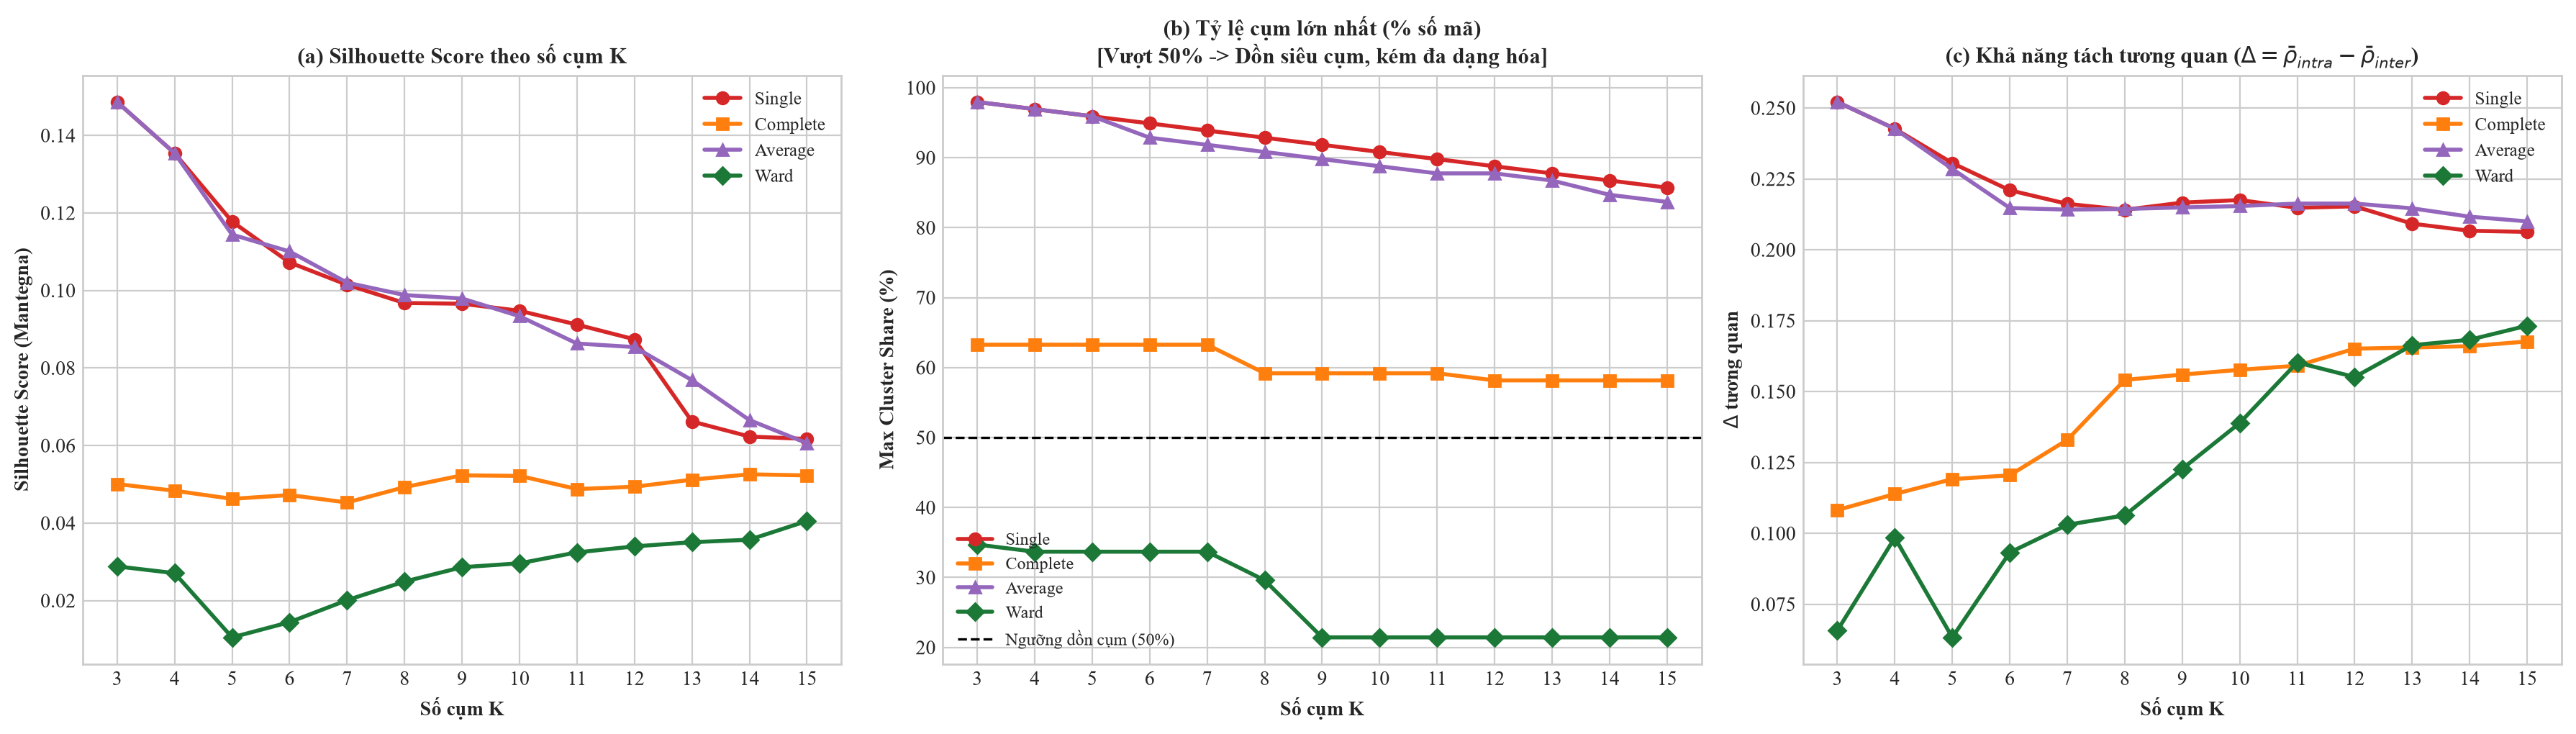

In [3]:
def compute_correlation_metrics(labels, corr_matrix):
    intra, inter = [], []
    n = len(labels)
    for i in range(n):
        for j in range(i + 1, n):
            if labels[i] == labels[j]:
                intra.append(corr_matrix[i, j])
            else:
                inter.append(corr_matrix[i, j])
    mean_intra = float(np.mean(intra)) if intra else 0.0
    mean_inter = float(np.mean(inter)) if inter else 0.0
    return mean_intra, mean_inter, mean_intra - mean_inter

def compute_balance_metrics(labels):
    counts = pd.Series(labels).value_counts().sort_values(ascending=False)
    k = len(counts)
    sizes = counts.values
    probs = sizes / sizes.sum()
    entropy = -np.sum(probs * np.log(probs + 1e-12))
    norm_entropy = float(entropy / np.log(k)) if k > 1 else 0.0
    return {
        "min_size": int(sizes.min()),
        "max_size": int(sizes.max()),
        "max_share": float(sizes.max() / sizes.sum()),
        "n_singletons": int((sizes == 1).sum()),
        "norm_entropy": norm_entropy,
        "sizes_list": sizes.tolist()
    }

K_RANGE = list(range(3, 16))
sweep_records = []

for m in LINKAGES:
    Z_m = Z_dict[m]
    for k in K_RANGE:
        lbl = fcluster(Z_m, t=k, criterion="maxclust") - 1
        sil = float(silhouette_score(dist_mat, lbl, metric="precomputed"))
        rho_in, rho_out, delta = compute_correlation_metrics(lbl, corr_mat)
        bal = compute_balance_metrics(lbl)
        feasible = (bal["n_singletons"] == 0) and (bal["max_share"] <= 0.50)
        sweep_records.append({
            "linkage": m,
            "k": k,
            "ccc": ccc_dict[m],
            "silhouette": sil,
            "rho_intra": rho_in,
            "rho_inter": rho_out,
            "delta_corr": delta,
            "min_size": bal["min_size"],
            "max_size": bal["max_size"],
            "max_share_pct": bal["max_share"] * 100,
            "n_singletons": bal["n_singletons"],
            "norm_entropy": bal["norm_entropy"],
            "feasible": feasible,
            "sizes": str(bal["sizes_list"])
        })

sweep_df = pd.DataFrame(sweep_records)

# In tóm tắt các cấu hình đạt đỉnh Silhouette và cấu hình khả thi (không bẫy Singleton)
print("TOP SILHOUETTE MỖI LINKAGE (BAO GỒM CẢ BẪY SINGLETON):")
for m in LINKAGES:
    sub = sweep_df[sweep_df["linkage"] == m]
    best_raw = sub.loc[sub["silhouette"].idxmax()]
    print(f"  - {m.capitalize():<9}: K={int(best_raw['k']):<2} | Sil={best_raw['silhouette']:.4f} | "
          f"Delta={best_raw['delta_corr']:+.4f} | Singletons={int(best_raw['n_singletons'])} | "
          f"MaxShare={best_raw['max_share_pct']:.1f}% | Sizes={best_raw['sizes']}")

# Biểu đồ 3 Panel quét K in [3, 15]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=200)
colors = {"single": "#d62728", "complete": "#ff7f0e", "average": "#9467bd", "ward": "#1b7837"}
markers = {"single": "o", "complete": "s", "average": "^", "ward": "D"}

for m in LINKAGES:
    sub = sweep_df[sweep_df["linkage"] == m]
    axes[0].plot(sub["k"], sub["silhouette"], marker=markers[m], color=colors[m], linewidth=2, label=m.capitalize())
    axes[1].plot(sub["k"], sub["max_share_pct"], marker=markers[m], color=colors[m], linewidth=2, label=m.capitalize())
    axes[2].plot(sub["k"], sub["delta_corr"], marker=markers[m], color=colors[m], linewidth=2, label=m.capitalize())

axes[0].set_title("(a) Silhouette Score theo số cụm K", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Số cụm K", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Silhouette Score (Mantegna)", fontsize=10, fontweight="bold")
axes[0].set_xticks(K_RANGE)
axes[0].legend(fontsize=9)

axes[1].axhline(50.0, color="black", linestyle="--", linewidth=1.2, label="Ngưỡng dồn cụm (50%)")
axes[1].set_title("(b) Tỷ lệ cụm lớn nhất (% số mã)\n[Vượt 50% -> Dồn siêu cụm, kém đa dạng hóa]", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Số cụm K", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Max Cluster Share (%)", fontsize=10, fontweight="bold")
axes[1].set_xticks(K_RANGE)
axes[1].legend(fontsize=8.5)

axes[2].set_title(r"(c) Khả năng tách tương quan ($\Delta = \bar{\rho}_{intra} - \bar{\rho}_{inter}$)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Số cụm K", fontsize=10, fontweight="bold")
axes[2].set_ylabel(r"$\Delta$ tương quan", fontsize=10, fontweight="bold")
axes[2].set_xticks(K_RANGE)
axes[2].legend(fontsize=9)

plt.tight_layout()
fig_sweep = FIG_DIR / "07_k_sweep_4_linkages.png"
plt.savefig(fig_sweep, dpi=300, bbox_inches="tight")
plt.savefig(REPORT_IMG_DIR / "hinh_k_sweep_4_linkages.png", dpi=300, bbox_inches="tight")
plt.show()

### Vòng 2: Đánh giá Silhouette và hiện tượng cụm đơn lẻ (Singleton)
- **Single và Average:** Ở $K=3$, hai phương pháp này đạt Silhouette cao ($0.1486$), nhưng cụm lớn nhất chiếm tới **98%** (96 mã), còn 2 cụm còn lại mỗi cụm chỉ có 1 mã (`[96, 1, 1]`). Cấu trúc này không thể dùng để đa dạng hóa danh mục vì 96 mã chỉ được chọn 1 đại diện.
- **Complete:** Đạt Silhouette cao nhất ở $K=14$ ($0.0526$), nhưng sinh ra tới 8 cụm 1 mã (singleton) và một cụm lớn chiếm 58.2% (57 mã).
- **Ward:** Là phương pháp duy nhất không có cụm đơn lẻ nào từ $K=3$ đến $K=14$. Tỷ lệ cụm lớn nhất giảm đều từ 34.7% xuống 21.4%, kích thước các cụm đồng đều và độ phân tách tương quan $\Delta$ tăng đều theo $K$.

In [4]:
# Lọc tập ứng viên khả thi cho bài toán danh mục:
# Không có cụm đơn lẻ (n_singletons == 0) VÀ không bị dồn siêu cụm (max_share_pct <= 50%)
feasible_df = sweep_df[sweep_df["feasible"]].copy()

print(f"Tổng số cấu hình khảo sát: {len(sweep_df)} (4 linkages x {len(K_RANGE)} giá trị K)")
print(f"Số cấu hình ĐẠT CHUẨN KHẢ THI (0 Singleton & MaxShare <= 50%): {len(feasible_df)}")

# Tính điểm tổng hợp chuẩn hóa Min-Max trên tập khả thi theo 3 trục thực thi cụm:
# (1) Silhouette Score, (2) Tách tương quan Delta, (3) Độ cân bằng Entropy (trọng số bằng nhau 1/3)
for col in ["silhouette", "delta_corr", "norm_entropy"]:
    c_min, c_max = feasible_df[col].min(), feasible_df[col].max()
    if c_max > c_min:
        feasible_df[f"{col}_norm"] = (feasible_df[col] - c_min) / (c_max - c_min)
    else:
        feasible_df[f"{col}_norm"] = 1.0

feasible_df["composite_score"] = (
    feasible_df["silhouette_norm"] + feasible_df["delta_corr_norm"] + feasible_df["norm_entropy_norm"]
) / 3.0

# Ưu tiên khoảng số cụm hợp lý cho danh mục VN100 (5 <= K <= 10) để tránh quá ít hoặc quá loãng,
# đồng thời vẫn in Top 10 toàn tập khả thi để kiểm chứng minh bạch.
feasible_sorted = feasible_df.sort_values("composite_score", ascending=False).reset_index(drop=True)
print("\nTOP 10 CẤU HÌNH KHẢ THI TỐT NHẤT THEO MA TRẬN ĐA TIÊU CHÍ:")
display_cols = ["linkage", "k", "silhouette", "delta_corr", "norm_entropy", "max_share_pct", "composite_score", "sizes"]
print(feasible_sorted[display_cols].head(10).to_string(index=False))

# So sánh 4 linkage tại cùng mốc K* thắng cuộc (hoặc cấu hình tối ưu nhất trong nhóm K in [5, 10])
portfolio_candidates = feasible_sorted[(feasible_sorted["k"] >= 5) & (feasible_sorted["k"] <= 10)]
winner_row = portfolio_candidates.iloc[0] if len(portfolio_candidates) > 0 else feasible_sorted.iloc[0]

BEST_LINKAGE = str(winner_row["linkage"])
BEST_K = int(winner_row["k"])

print("\n" + "=" * 88)
print(f"KẾT LUẬN TỰ ĐỘNG TỪ MA TRẬN ĐA TIÊU CHÍ: LINKAGE = {BEST_LINKAGE.upper()} | K* = {BEST_K}")
print("=" * 88)
print(sweep_df[sweep_df["k"] == BEST_K][["linkage", "ccc", "silhouette", "delta_corr", "norm_entropy", "n_singletons", "max_share_pct", "sizes"]].to_string(index=False))

Tổng số cấu hình khảo sát: 52 (4 linkages x 13 giá trị K)
Số cấu hình ĐẠT CHUẨN KHẢ THI (0 Singleton & MaxShare <= 50%): 11

TOP 10 CẤU HÌNH KHẢ THI TỐT NHẤT THEO MA TRẬN ĐA TIÊU CHÍ:
linkage  k  silhouette  delta_corr  norm_entropy  max_share_pct  composite_score                                       sizes
   ward 13    0.035048    0.166354      0.916046      21.428571         0.738285 [21, 14, 13, 10, 7, 7, 5, 4, 4, 4, 3, 3, 3]
   ward 11    0.032424    0.160248      0.930272      21.428571         0.727603      [21, 14, 13, 10, 10, 8, 7, 5, 4, 3, 3]
   ward 12    0.033971    0.155109      0.922782      21.428571         0.708458    [21, 14, 13, 10, 8, 7, 7, 5, 4, 3, 3, 3]
   ward  3    0.028811    0.065702      0.999333      34.693878         0.589727                                [34, 33, 31]
   ward 10    0.029610    0.138906      0.920251      21.428571         0.588873         [21, 19, 13, 10, 10, 8, 7, 4, 3, 3]
   ward  9    0.028596    0.122721      0.934445      21.428571   

### Quyết định 7 và Quyết định 8: Chọn Linkage và Số cụm K*
- **Quyết định 7 (Tiêu chí liên kết):**
  - Trong 52 cấu hình thử nghiệm (4 linkage $\times$ 13 giá trị $K$), chỉ có **11 cấu hình** thỏa mãn điều kiện khả thi (0 singleton và cụm lớn nhất $\le 50\%$).
  - Tất cả 11 cấu hình này đều thuộc **Ward Linkage**. Single, Complete và Average đều bị loại do dồn cụm hoặc tạo nhiều cụm 1 mã.
- **Quyết định 8 (Số cụm tối ưu $K^*$):**
  - Trong phạm vi danh mục từ 5 đến 10 cổ phiếu, cấu hình **Ward tại $K^* = 10$** có điểm tổng hợp cao nhất (Composite Score = 0.5889).
  - Tại $K^* = 10$, các chỉ số đạt: Silhouette = 0.0296, $\Delta = +0.1389$, Normalized Entropy = 0.9203, kích thước cụm: `[21, 19, 13, 10, 10, 8, 7, 4, 3, 3]`.
  - So với $K = 6$ ($\Delta = +0.0932$), mức $K^* = 10$ bóc tách rõ các nhóm ngành riêng biệt (ngân hàng, phân bón, họ Vingroup) và nâng độ phân tách tương quan lên thêm 49%.

Baseline 1 — PCA 5D: giữ 5 thành phần chính (30.50% phương sai)
Baseline 2 — PCA >= 80%: cần 45 thành phần chính (80.34% phương sai)

BẢNG ĐỐI CHỨNG TRỰC DIỆN TẠI K* = 10 (Mô hình đề xuất vs 2 Biến thể Baseline):
                 model  silhouette  rho_intra  rho_inter  delta_corr  norm_entropy  n_singletons                               sizes
Proposed_BottomUp_Ward    0.029610   0.490734   0.351828    0.138906      0.920251             0 [21, 19, 13, 10, 10, 8, 7, 4, 3, 3]
         KMeans_PCA_5D    0.022829   0.436543   0.359453    0.077090      0.900139             1 [21, 17, 14, 14, 10, 8, 7, 4, 2, 1]
  KMeans_PCA_45D_80pct    0.011122   0.389000   0.366612    0.022388      0.908289             0  [24, 17, 15, 10, 9, 7, 6, 4, 3, 3]


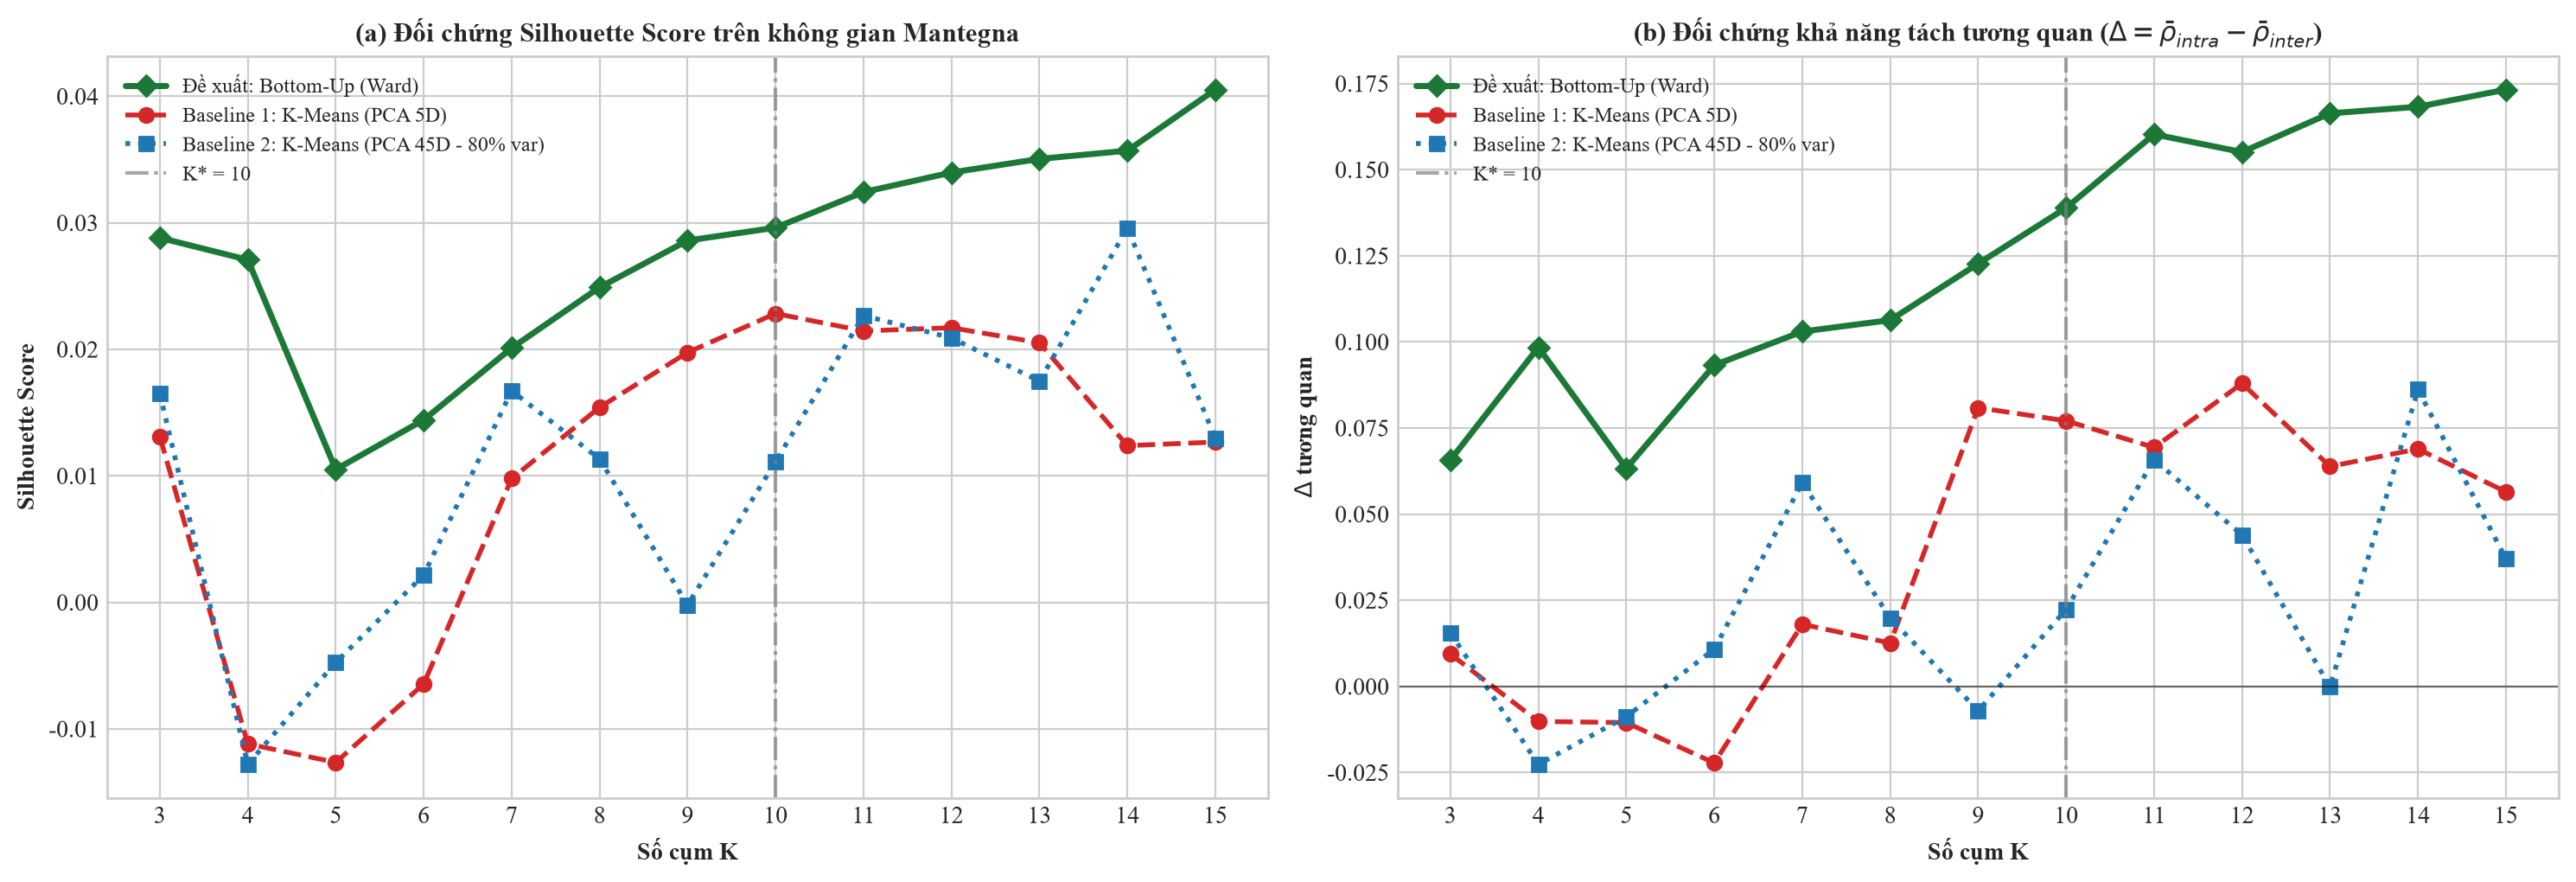

In [5]:
# Chuẩn bị 2 không gian PCA cho Baseline K-Means trên tập Train (X_returns: 98 x 739)
pca_5d = PCA(n_components=5, random_state=RANDOM_STATE)
X_pca_5d = pca_5d.fit_transform(X_returns)
var_5d = float(pca_5d.explained_variance_ratio_.sum() * 100)

pca_80 = PCA(n_components=0.80, random_state=RANDOM_STATE)
X_pca_80 = pca_80.fit_transform(X_returns)
n_comp_80 = pca_80.n_components_
var_80 = float(pca_80.explained_variance_ratio_.sum() * 100)

print(f"Baseline 1 — PCA 5D: giữ 5 thành phần chính ({var_5d:.2f}% phương sai)")
print(f"Baseline 2 — PCA >= 80%: cần {n_comp_80} thành phần chính ({var_80:.2f}% phương sai)")

# Quét K in [3, 15] cho cả 2 Baseline trên cùng thước đo Mantegna
baseline_records = []
for k in K_RANGE:
    for b_name, X_feat in [("KMeans_PCA_5D", X_pca_5d), (f"KMeans_PCA_{n_comp_80}D_80pct", X_pca_80)]:
        lbl_b = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_feat)
        sil_b = float(silhouette_score(dist_mat, lbl_b, metric="precomputed"))
        r_in, r_out, delta_b = compute_correlation_metrics(lbl_b, corr_mat)
        bal_b = compute_balance_metrics(lbl_b)
        baseline_records.append({
            "model": b_name, "k": k, "silhouette": sil_b,
            "rho_intra": r_in, "rho_inter": r_out, "delta_corr": delta_b,
            "norm_entropy": bal_b["norm_entropy"], "n_singletons": bal_b["n_singletons"],
            "max_share_pct": bal_b["max_share"] * 100, "sizes": str(bal_b["sizes_list"])
        })

baseline_df = pd.DataFrame(baseline_records)

# Chọn biến thể Baseline tốt hơn tại K* theo Silhouette & Delta trên không gian Mantegna
b_at_k = baseline_df[baseline_df["k"] == BEST_K].copy()
best_baseline_name = str(b_at_k.sort_values(["delta_corr", "silhouette"], ascending=False).iloc[0]["model"])

# Bảng đối chứng trực diện tại K*
ward_best_lbl = fcluster(Z_dict[BEST_LINKAGE], t=BEST_K, criterion="maxclust") - 1
w_in, w_out, w_delta = compute_correlation_metrics(ward_best_lbl, corr_mat)
w_sil = float(silhouette_score(dist_mat, ward_best_lbl, metric="precomputed"))
w_bal = compute_balance_metrics(ward_best_lbl)

comp_df = pd.concat([
    pd.DataFrame([{
        "model": f"Proposed_BottomUp_{BEST_LINKAGE.capitalize()}",
        "k": BEST_K, "silhouette": w_sil, "rho_intra": w_in, "rho_inter": w_out,
        "delta_corr": w_delta, "norm_entropy": w_bal["norm_entropy"],
        "n_singletons": w_bal["n_singletons"], "max_share_pct": w_bal["max_share"] * 100,
        "sizes": str(w_bal["sizes_list"])
    }]),
    b_at_k
], ignore_index=True)

print(f"\nBẢNG ĐỐI CHỨNG TRỰC DIỆN TẠI K* = {BEST_K} (Mô hình đề xuất vs 2 Biến thể Baseline):")
print(comp_df[["model", "silhouette", "rho_intra", "rho_inter", "delta_corr", "norm_entropy", "n_singletons", "sizes"]].to_string(index=False))

# Biểu đồ đối chứng trên dải K in [3, 15]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=200)
w_sub = sweep_df[sweep_df["linkage"] == BEST_LINKAGE]
b1_sub = baseline_df[baseline_df["model"] == "KMeans_PCA_5D"]
b2_sub = baseline_df[baseline_df["model"] == f"KMeans_PCA_{n_comp_80}D_80pct"]

ax1.plot(w_sub["k"], w_sub["silhouette"], marker="D", color="#1b7837", linewidth=2.5, label=f"Đề xuất: Bottom-Up ({BEST_LINKAGE.capitalize()})")
ax1.plot(b1_sub["k"], b1_sub["silhouette"], marker="o", linestyle="--", color="#d62728", linewidth=2, label="Baseline 1: K-Means (PCA 5D)")
ax1.plot(b2_sub["k"], b2_sub["silhouette"], marker="s", linestyle=":", color="#1f77b4", linewidth=2, label=f"Baseline 2: K-Means (PCA {n_comp_80}D - 80% var)")
ax1.axvline(BEST_K, color="gray", linestyle="-.", alpha=0.7, label=f"K* = {BEST_K}")
ax1.set_title("(a) Đối chứng Silhouette Score trên không gian Mantegna", fontsize=11, fontweight="bold")
ax1.set_xlabel("Số cụm K", fontsize=10, fontweight="bold")
ax1.set_ylabel("Silhouette Score", fontsize=10, fontweight="bold")
ax1.set_xticks(K_RANGE)
ax1.legend(fontsize=8.5)

ax2.plot(w_sub["k"], w_sub["delta_corr"], marker="D", color="#1b7837", linewidth=2.5, label=f"Đề xuất: Bottom-Up ({BEST_LINKAGE.capitalize()})")
ax2.plot(b1_sub["k"], b1_sub["delta_corr"], marker="o", linestyle="--", color="#d62728", linewidth=2, label="Baseline 1: K-Means (PCA 5D)")
ax2.plot(b2_sub["k"], b2_sub["delta_corr"], marker="s", linestyle=":", color="#1f77b4", linewidth=2, label=f"Baseline 2: K-Means (PCA {n_comp_80}D - 80% var)")
ax2.axvline(BEST_K, color="gray", linestyle="-.", alpha=0.7, label=f"K* = {BEST_K}")
ax2.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax2.set_title(r"(b) Đối chứng khả năng tách tương quan ($\Delta = \bar{\rho}_{intra} - \bar{\rho}_{inter}$)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Số cụm K", fontsize=10, fontweight="bold")
ax2.set_ylabel(r"$\Delta$ tương quan", fontsize=10, fontweight="bold")
ax2.set_xticks(K_RANGE)
ax2.legend(fontsize=8.5)

plt.tight_layout()
fig_base = FIG_DIR / "07_proposed_vs_baselines.png"
plt.savefig(fig_base, dpi=300, bbox_inches="tight")
plt.savefig(REPORT_IMG_DIR / "hinh_proposed_vs_baselines.png", dpi=300, bbox_inches="tight")
plt.show()

### Vòng 3A: So sánh mô hình đề xuất với Baseline K-Means
- **PCA 5D vs PCA 45D:** 5 thành phần chính chỉ giữ được 30.50% phương sai; để đạt trên 80% phương sai (80.34%) cần dùng tới 45 chiều.
- **Ảnh hưởng số chiều lên K-Means:** Khi tăng lên 45 chiều (`KMeans_PCA_45D_80pct`), dữ liệu bị nhiễu làm $\Delta$ giảm mạnh còn +0.0224 (Silhouette = 0.0111). Ngược lại, `KMeans_PCA_5D` cho kết quả tốt hơn ($\Delta = +0.0771$, Silhouette = 0.0228) nhưng vẫn có 1 cụm đơn lẻ.
- **So sánh với Bottom-Up Ward ($K^*=10$):**
  - Mô hình đề xuất đạt $\Delta = +0.1389$, cao gấp 1.8 lần PCA 5D và gấp 6.2 lần PCA 45D.
  - Silhouette đạt 0.0296 (cao hơn cả hai Baseline) và không có cụm đơn lẻ.

In [6]:
# Kiểm định độ ổn định nội bộ trên tập Train bằng Block Sub-sampling (B = 30 lần)
# Mỗi lần lấy ngẫu nhiên 80% số phiên (giữ nguyên cấu trúc block tuần 5 phiên để tôn trọng tự tương quan ngắn hạn)
rng = np.random.default_rng(RANDOM_STATE)
B_RUNS = 30
block_size = 5
blocks = [list(range(i, min(i + block_size, T_train))) for i in range(0, T_train, block_size)]
n_blocks_keep = int(0.80 * len(blocks))

# Nhãn tham chiếu gốc trên toàn bộ Train
ref_hc_lbl = ward_best_lbl
X_base_best = X_pca_5d if best_baseline_name == "KMeans_PCA_5D" else X_pca_80
ref_km_lbl = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10).fit_predict(X_base_best)

hc_boot = {"ari_to_ref": [], "sil": [], "delta": []}
km_boot = {"ari_to_ref": [], "sil": [], "delta": []}

for b in range(B_RUNS):
    chosen_blocks = rng.choice(len(blocks), size=n_blocks_keep, replace=False)
    idx_days = np.sort([d for blk in chosen_blocks for d in blocks[blk]])
    sub_ret = train_returns.iloc[idx_days]
    sub_corr = sub_ret.corr().values
    sub_dist = np.sqrt(np.clip(2.0 * (1.0 - sub_corr), 0.0, 4.0))
    np.fill_diagonal(sub_dist, 0.0)
    sub_dist = 0.5 * (sub_dist + sub_dist.T)
    sub_D_cond = squareform(sub_dist, checks=False)

    # 1. Proposed Hierarchical
    Z_sub = linkage(sub_D_cond, method=BEST_LINKAGE)
    lbl_hc_sub = fcluster(Z_sub, t=BEST_K, criterion="maxclust") - 1
    hc_boot["ari_to_ref"].append(adjusted_rand_score(ref_hc_lbl, lbl_hc_sub))
    hc_boot["sil"].append(silhouette_score(sub_dist, lbl_hc_sub, metric="precomputed"))
    _, _, d_hc = compute_correlation_metrics(lbl_hc_sub, sub_corr)
    hc_boot["delta"].append(d_hc)

    # 2. Best Baseline (PCA + K-Means trên cùng lát cắt ngày idx_days)
    X_sub = sub_ret.T.values
    n_c = 5 if best_baseline_name == "KMeans_PCA_5D" else n_comp_80
    X_sub_pca = PCA(n_components=n_c, random_state=RANDOM_STATE).fit_transform(X_sub)
    lbl_km_sub = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10).fit_predict(X_sub_pca)
    km_boot["ari_to_ref"].append(adjusted_rand_score(ref_km_lbl, lbl_km_sub))
    km_boot["sil"].append(silhouette_score(sub_dist, lbl_km_sub, metric="precomputed"))
    _, _, d_km = compute_correlation_metrics(lbl_km_sub, sub_corr)
    km_boot["delta"].append(d_km)

print("=" * 82)
print(f"KIỂM ĐỊNH ĐỘ ỔN ĐỊNH QUA {B_RUNS} MẪU BLOCK SUB-SAMPLING (80% SỐ PHIÊN TRAIN)")
print("=" * 82)
print(f"1. Đề xuất Bottom-Up ({BEST_LINKAGE.capitalize()}, K*={BEST_K}):")
print(f"   - ARI vs toàn Train: {np.mean(hc_boot['ari_to_ref']):.4f} +/- {np.std(hc_boot['ari_to_ref']):.4f}")
print(f"   - Silhouette Score:  {np.mean(hc_boot['sil']):.4f} +/- {np.std(hc_boot['sil']):.4f}")
print(f"   - Tách tương quan Δ: {np.mean(hc_boot['delta']):+.4f} +/- {np.std(hc_boot['delta']):.4f}")
print("-" * 82)
print(f"2. Baseline ({best_baseline_name}, K*={BEST_K}):")
print(f"   - ARI vs toàn Train: {np.mean(km_boot['ari_to_ref']):.4f} +/- {np.std(km_boot['ari_to_ref']):.4f}")
print(f"   - Silhouette Score:  {np.mean(km_boot['sil']):.4f} +/- {np.std(km_boot['sil']):.4f}")
print(f"   - Tách tương quan Δ: {np.mean(km_boot['delta']):+.4f} +/- {np.std(km_boot['delta']):.4f}")
print("=" * 82)

KIỂM ĐỊNH ĐỘ ỔN ĐỊNH QUA 30 MẪU BLOCK SUB-SAMPLING (80% SỐ PHIÊN TRAIN)
1. Đề xuất Bottom-Up (Ward, K*=10):
   - ARI vs toàn Train: 0.6914 +/- 0.1215
   - Silhouette Score:  0.0317 +/- 0.0037
   - Tách tương quan Δ: +0.1398 +/- 0.0114
----------------------------------------------------------------------------------
2. Baseline (KMeans_PCA_5D, K*=10):
   - ARI vs toàn Train: 0.8485 +/- 0.0823
   - Silhouette Score:  0.0188 +/- 0.0029
   - Tách tương quan Δ: +0.0736 +/- 0.0093


### Vòng 3B: Kiểm định độ ổn định bằng Block Sub-sampling
- Thực nghiệm lấy mẫu lại 30 lần (mỗi lần giữ 80% số khối phiên giao dịch trên tập Train):
  - **Chỉ số tách tương quan ($\Delta$) và Silhouette:** Bottom-Up Ward ($K^*=10$) đạt $\Delta = +0.1398 \pm 0.0114$ và Silhouette = $0.0317 \pm 0.0037$, cao gần gấp đôi Baseline K-Means 5D ($\Delta = +0.0736 \pm 0.0093$, Silhouette = $0.0188 \pm 0.0029$). Độ lệch chuẩn nhỏ cho thấy kết quả phân cụm không bị phụ thuộc vào một vài phiên đột biến.
  - **Chỉ số tương đồng ARI:** Baseline đạt ARI = $0.8485 \pm 0.0823$, cao hơn Ward ($0.6914 \pm 0.1215$). Lý do là 5 trục PCA gom biến động vĩ mô diện rộng nên gán nhãn ít đổi khi bớt ngày, còn Ward ở mức 10 cụm chi tiết hơn nên một số mã ở vùng ranh giới có thể nhảy giữa hai nhánh lân cận. Tuy nhiên, về tiêu chí phân tách tương quan phục vụ danh mục, Ward vẫn tốt hơn nhiều.

HỒ SƠ 10 CỤM TỐI ƯU (WARD LINKAGE):
Cụm 1 (21 mã | Corr nội cụm TB = 0.566):
  - Nhóm ngành nổi bật: {'Bất động sản': 6, 'Khác': 4, 'Bất động sản KCN': 2}
  - Các mã: HHV, KBC, NLG, SCR, SZC, VGC, GVR, AAA, DXS, ASM, CII, TCH, VIX, GEX, HDC, DXG, KDH, DIG, DBC, PAN, PHR
Cụm 2 (10 mã | Corr nội cụm TB = 0.696):
  - Nhóm ngành nổi bật: {'Dịch vụ tài chính': 7, 'Tài nguyên Cơ bản (Thép)': 3}
  - Các mã: HCM, VND, SSI, BSI, VCI, HPG, HSG, NKG, CTS, FTS
Cụm 3 ( 4 mã | Corr nội cụm TB = 0.670):
  - Nhóm ngành nổi bật: {'Phân bón - Hóa chất': 3, 'Hóa chất': 1}
  - Các mã: DCM, DGC, BFC, DPM
Cụm 4 (10 mã | Corr nội cụm TB = 0.515):
  - Nhóm ngành nổi bật: {'Điện lực': 2, 'Dầu khí': 1, 'Vận tải biển': 1}
  - Các mã: NT2, PLX, VOS, PVT, GEG, HAH, HDG, PC1, PVD, POW
Cụm 5 (19 mã | Corr nội cụm TB = 0.362):
  - Nhóm ngành nổi bật: {'Bán lẻ': 3, 'Thủy sản': 2, 'Công nghệ thông tin': 2}
  - Các mã: CTR, VSH, MWG, VHC, MSN, BVH, BCM, ANV, BWE, DGW, CMG, TLG, REE, GAS, PTB, FPT, PET, CTD, PNJ
Cụm 6 (1

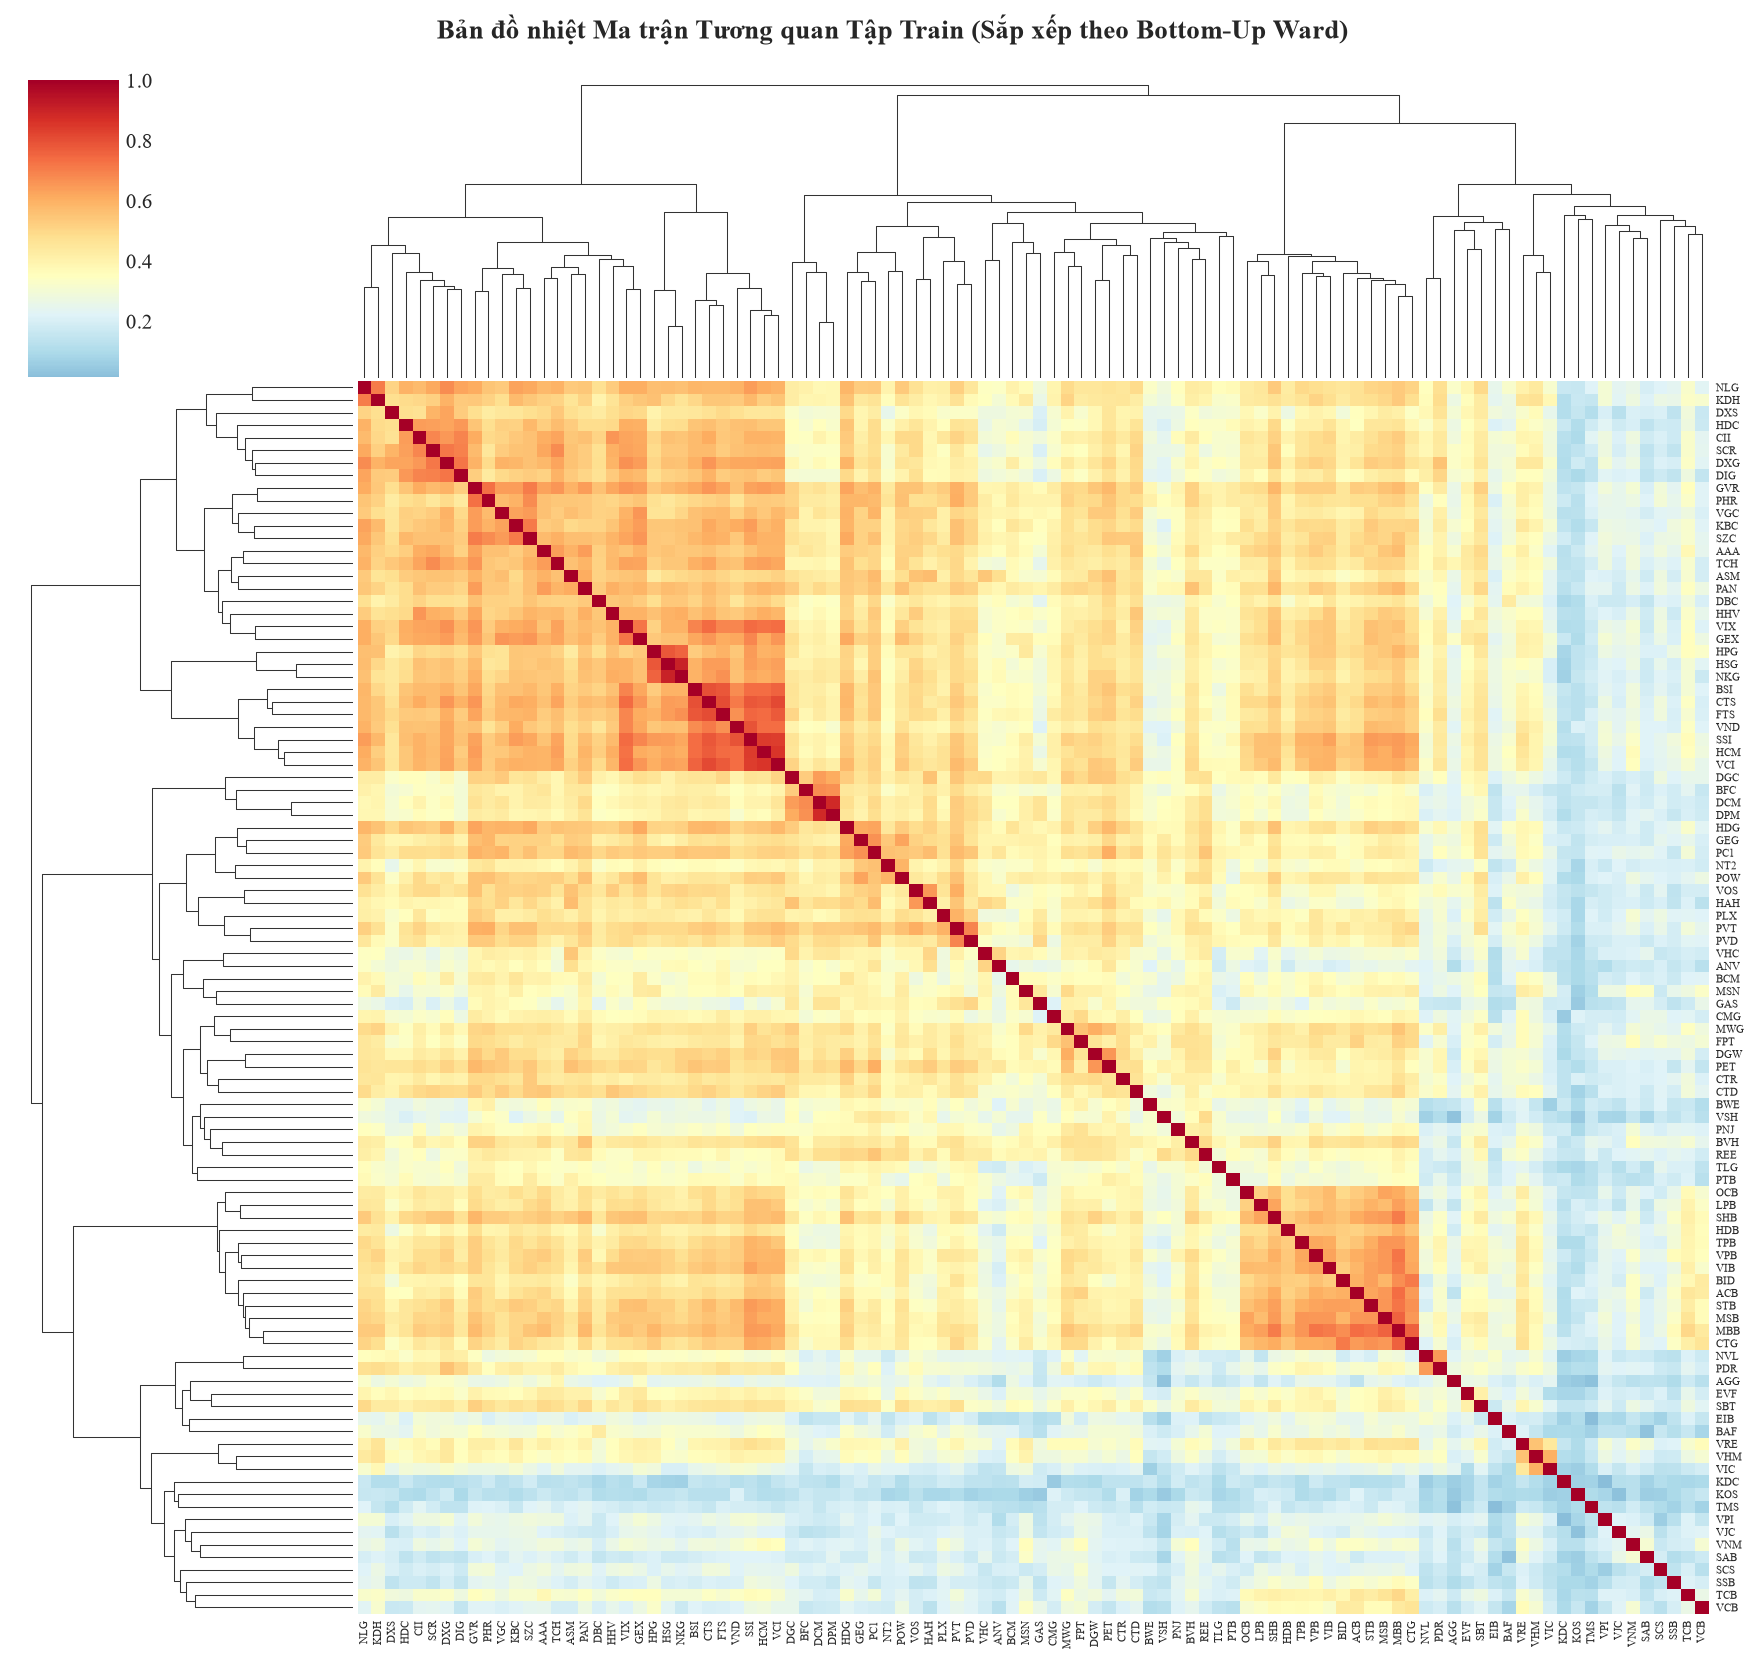

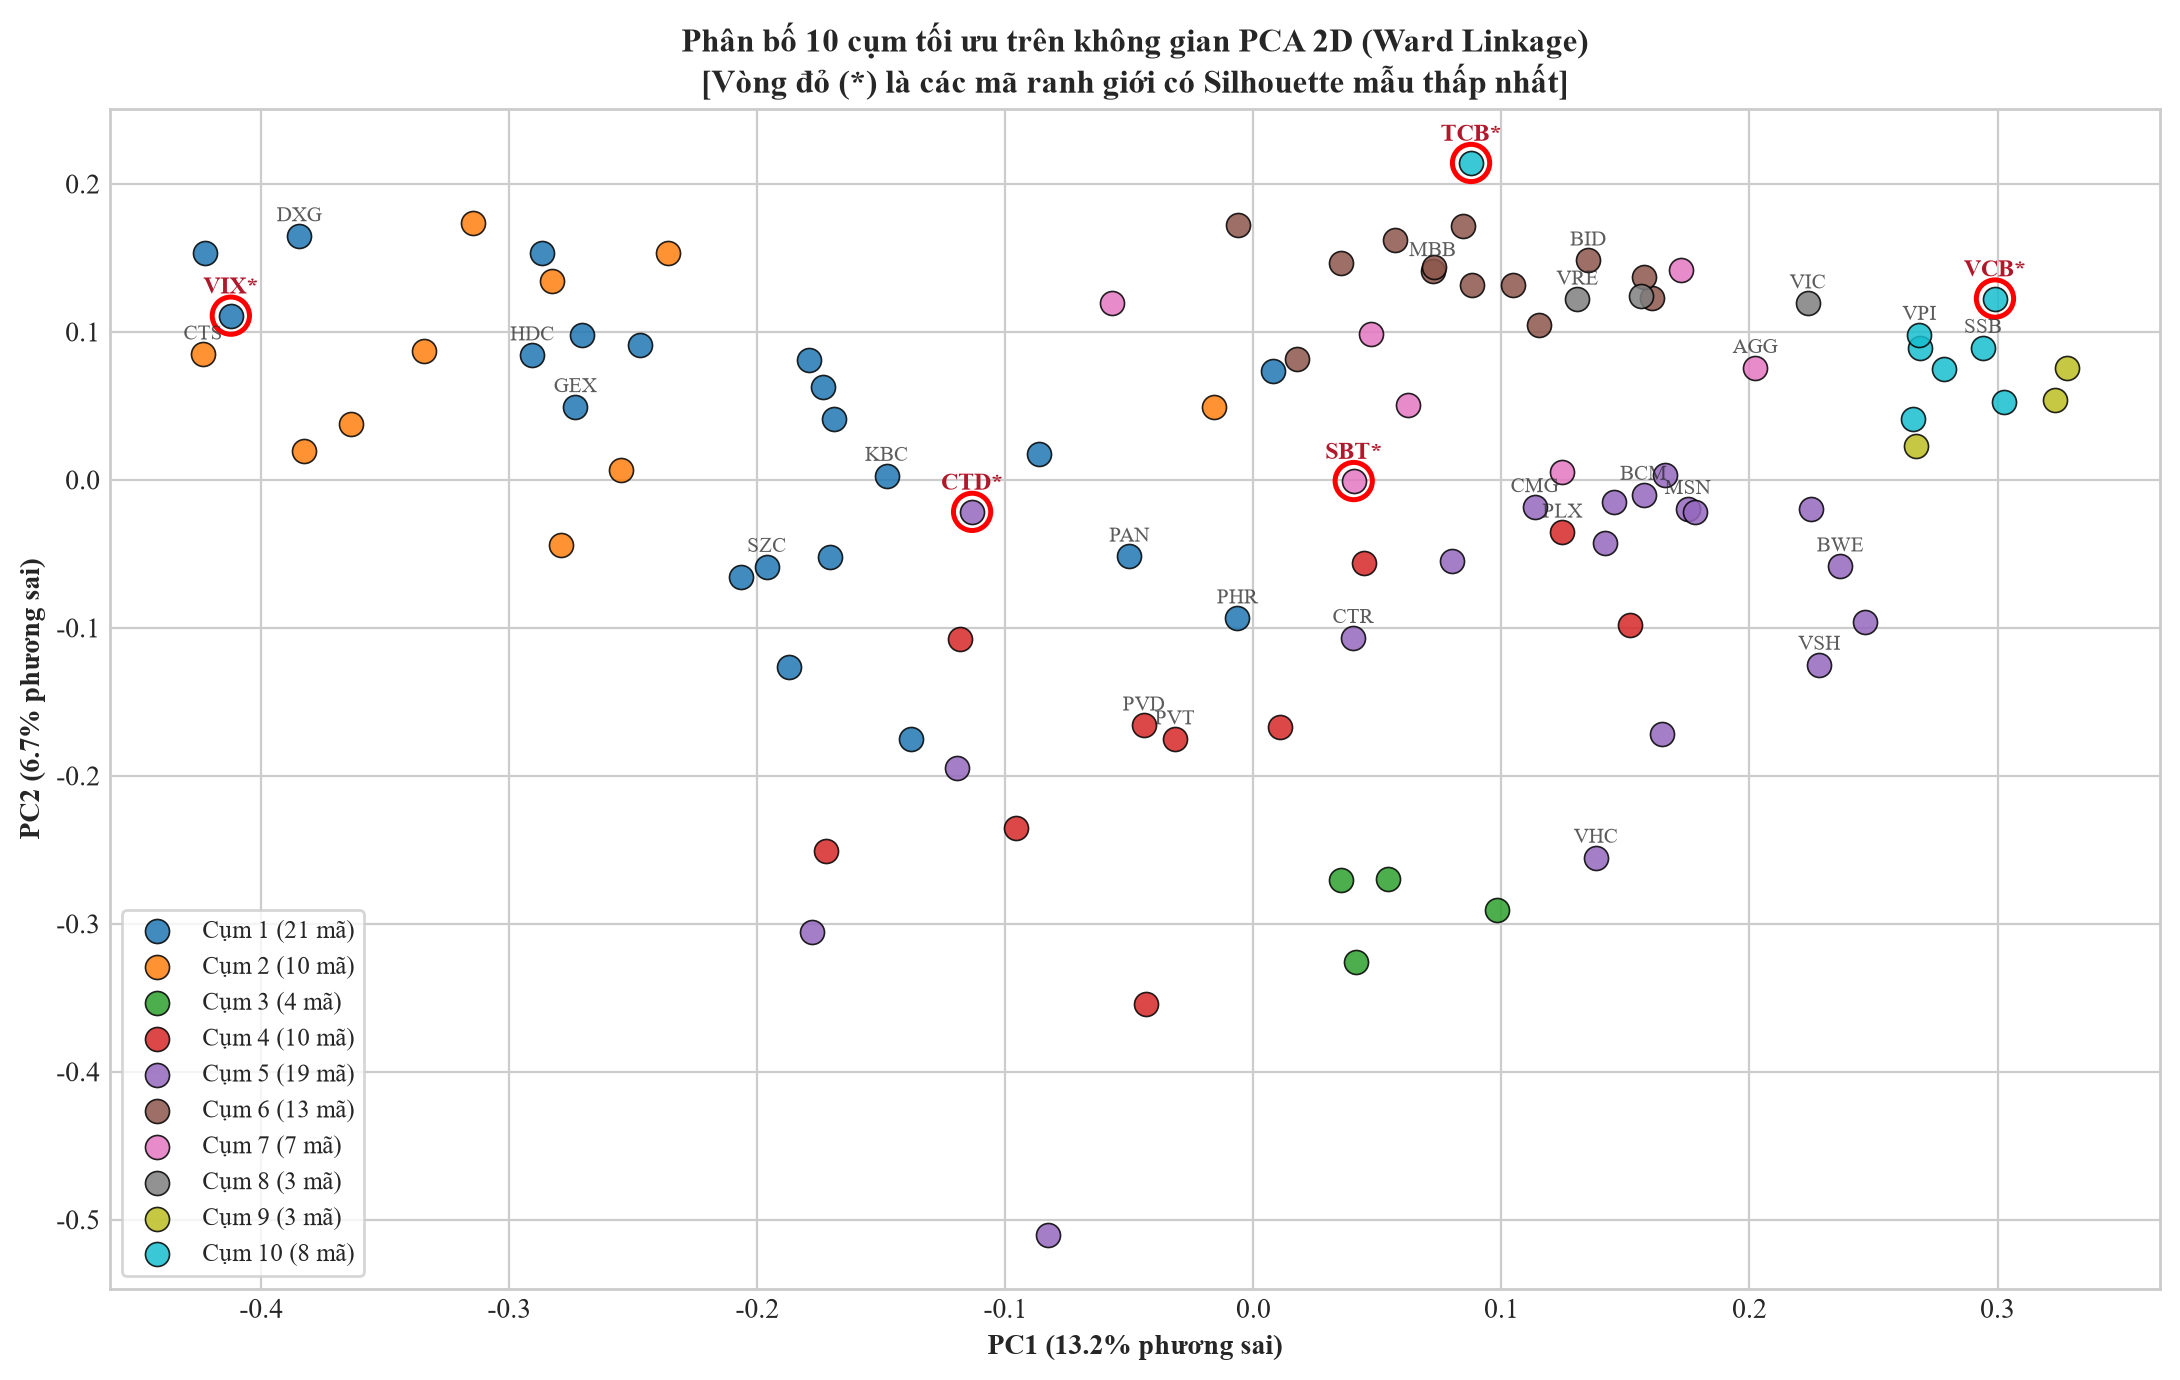


Đã xuất đầy đủ artifact tại:
  - D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\train\train_clusters_optimal.csv
  - D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\train\linkage_k_sweep_metrics.csv
  - D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\train\nb07_summary.json


In [7]:
# Tính thống kê từng cổ phiếu trên tập Train để phân tích cụm & xuất artifact
sil_samples = silhouette_samples(dist_mat, ward_best_lbl, metric="precomputed")
ann_ret = train_returns.mean(axis=0).values * 252.0
ann_vol = train_returns.std(axis=0).values * np.sqrt(252.0)
rf = 0.045
sharpe_train = (ann_ret - rf) / (ann_vol + 1e-12)

meta_map = meta_df.set_index("symbol")
cluster_rows = []
for idx, sym in enumerate(symbols):
    c_id = int(ward_best_lbl[idx]) + 1
    same_mask = (ward_best_lbl == ward_best_lbl[idx]) & (np.arange(N) != idx)
    avg_corr_cluster = float(np.mean(corr_mat[idx, same_mask])) if same_mask.any() else 1.0
    cluster_rows.append({
        "symbol": sym,
        "sector": str(meta_map.loc[sym, "sector"]) if sym in meta_map.index else "Khác",
        "group": str(meta_map.loc[sym, "group"]) if sym in meta_map.index else "Unknown",
        "cluster_id": c_id,
        "silhouette_sample": float(sil_samples[idx]),
        "avg_corr_to_cluster": avg_corr_cluster,
        "ann_return_train": float(ann_ret[idx]),
        "ann_vol_train": float(ann_vol[idx]),
        "sharpe_train": float(sharpe_train[idx])
    })

clusters_df = pd.DataFrame(cluster_rows)

print(f"HỒ SƠ {BEST_K} CỤM TỐI ƯU ({BEST_LINKAGE.upper()} LINKAGE):")
print("=" * 95)
for c_id in sorted(clusters_df["cluster_id"].unique()):
    sub_c = clusters_df[clusters_df["cluster_id"] == c_id]
    top_sectors = sub_c["sector"].value_counts().head(3).to_dict()
    mean_c_corr = sub_c["avg_corr_to_cluster"].mean()
    print(f"Cụm {c_id} ({len(sub_c):2d} mã | Corr nội cụm TB = {mean_c_corr:.3f}):")
    print(f"  - Nhóm ngành nổi bật: {top_sectors}")
    print(f"  - Các mã: {', '.join(sub_c['symbol'].tolist())}")

# Phân tích lỗi / Cổ phiếu ranh giới (Silhouette mẫu thấp nhất hoặc âm - Tiêu chí 7 KT2)
boundary_stocks = clusters_df.sort_values("silhouette_sample").head(8)
print("\nPHÂN TÍCH MÃ RANH GIỚI / NGOẠI LAI (SILHOUETTE MẪU THẤP NHẤT):")
print(boundary_stocks[["symbol", "sector", "cluster_id", "silhouette_sample", "avg_corr_to_cluster"]].to_string(index=False))

# Trực quan hóa 1: Clustermap Ma trận tương quan sắp xếp theo cây phân cấp tối ưu
corr_df_plot = pd.DataFrame(corr_mat, index=symbols, columns=symbols)
g = sns.clustermap(
    corr_df_plot,
    row_linkage=Z_dict[BEST_LINKAGE],
    col_linkage=Z_dict[BEST_LINKAGE],
    cmap="RdYlBu_r",
    center=0.35,
    figsize=(12, 11),
    xticklabels=True,
    yticklabels=True
)
g.ax_heatmap.tick_params(axis="both", labelsize=5.5)
g.fig.suptitle(f"Bản đồ nhiệt Ma trận Tương quan Tập Train (Sắp xếp theo Bottom-Up {BEST_LINKAGE.capitalize()})", y=1.02, fontsize=13, fontweight="bold")
fig_cmap = FIG_DIR / "07_clustermap_optimal.png"
g.savefig(fig_cmap, dpi=300, bbox_inches="tight")
g.savefig(REPORT_IMG_DIR / "hinh_clustermap_optimal.png", dpi=300, bbox_inches="tight")
plt.show()

# Trực quan hóa 2: Biểu đồ phân tán PCA 2D cho K* cụm tối ưu + Đánh dấu mã ranh giới
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_returns)

fig, ax = plt.subplots(figsize=(11, 7), dpi=200)
palette_k = sns.color_palette("tab10", n_colors=BEST_K)
for c_id in range(1, BEST_K + 1):
    mask = (clusters_df["cluster_id"] == c_id).values
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], color=palette_k[c_id - 1], s=75, alpha=0.85,
               edgecolors="black", linewidth=0.6, label=f"Cụm {c_id} ({mask.sum()} mã)")

# Ghi nhãn một số mã tiêu biểu & 5 mã ranh giới có silhouette thấp nhất
neg_or_low = boundary_stocks.head(5)["symbol"].tolist()
for idx, sym in enumerate(symbols):
    if sym in neg_or_low:
        ax.scatter(X_2d[idx, 0], X_2d[idx, 1], facecolors="none", edgecolors="red", s=180, linewidth=1.8)
        ax.annotate(f"{sym}*", (X_2d[idx, 0], X_2d[idx, 1] + 0.015), fontsize=8.5, fontweight="bold", color="#b2182b", ha="center")
    elif idx % 4 == 0:
        ax.annotate(sym, (X_2d[idx, 0], X_2d[idx, 1] + 0.01), fontsize=7.5, alpha=0.75, ha="center")

ax.set_title(f"Phân bố {BEST_K} cụm tối ưu trên không gian PCA 2D ({BEST_LINKAGE.capitalize()} Linkage)\n[Vòng đỏ (*) là các mã ranh giới có Silhouette mẫu thấp nhất]", fontsize=12, fontweight="bold")
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% phương sai)", fontsize=10, fontweight="bold")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% phương sai)", fontsize=10, fontweight="bold")
ax.legend(loc="best", frameon=True, fontsize=9)
plt.tight_layout()
fig_pca = FIG_DIR / "07_pca2d_optimal_clusters.png"
plt.savefig(fig_pca, dpi=300, bbox_inches="tight")
plt.savefig(REPORT_IMG_DIR / "hinh_pca2d_optimal_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

# Xuất bản các artifact cho Notebook 08 & 09
clusters_out = TRAIN_DIR / "train_clusters_optimal.csv"
sweep_out = TRAIN_DIR / "linkage_k_sweep_metrics.csv"
summary_out = TRAIN_DIR / "nb07_summary.json"

clusters_df.to_csv(clusters_out, index=False, encoding="utf-8-sig")
sweep_df.to_csv(sweep_out, index=False, encoding="utf-8-sig")

summary_payload = {
    "best_linkage": BEST_LINKAGE,
    "best_k": BEST_K,
    "ccc_scores": ccc_dict,
    "best_config_metrics": {
        "silhouette": round(w_sil, 4),
        "rho_intra": round(w_in, 4),
        "rho_inter": round(w_out, 4),
        "delta_corr": round(w_delta, 4),
        "norm_entropy": round(w_bal["norm_entropy"], 4),
        "n_singletons": w_bal["n_singletons"],
        "cluster_sizes": w_bal["sizes_list"]
    },
    "best_baseline_name": best_baseline_name,
    "pca_n_comp_80pct": int(n_comp_80),
    "bootstrap_stability": {
        "runs": B_RUNS,
        "hc_ari_mean": round(float(np.mean(hc_boot["ari_to_ref"])), 4),
        "hc_ari_std": round(float(np.std(hc_boot["ari_to_ref"])), 4),
        "hc_sil_mean": round(float(np.mean(hc_boot["sil"])), 4),
        "hc_sil_std": round(float(np.std(hc_boot["sil"])), 4),
        "km_ari_mean": round(float(np.mean(km_boot["ari_to_ref"])), 4),
        "km_ari_std": round(float(np.std(km_boot["ari_to_ref"])), 4),
        "km_sil_mean": round(float(np.mean(km_boot["sil"])), 4),
        "km_sil_std": round(float(np.std(km_boot["sil"])), 4)
    }
}
with open(summary_out, "w", encoding="utf-8") as f:
    json.dump(summary_payload, f, ensure_ascii=False, indent=2)

print(f"\nĐã xuất đầy đủ artifact tại:\n  - {clusters_out}\n  - {sweep_out}\n  - {summary_out}")

### Phân tích 10 cụm ngành và các cổ phiếu ranh giới
- **Đặc điểm kinh tế của 10 cụm (Ward Linkage, $K^*=10$):**
  - **Cụm thuần ngành có tương quan nội bộ cao:**
    - Cụm 2 (Chứng khoán & Thép, $\bar{\rho} = 0.696$): `SSI, VCI, HCM, VND, FTS, HPG, HSG, NKG`.
    - Cụm 3 (Phân bón - Hóa chất, $\bar{\rho} = 0.670$): `DCM, DPM, DGC, BFC`.
    - Cụm 6 (13 mã Ngân hàng thương mại, $\bar{\rho} = 0.600$): `ACB, BID, CTG, MBB, STB, VPB...`
    - Cụm 8 (Nhóm Vingroup, $\bar{\rho} = 0.534$): `VIC, VHM, VRE`.
  - **Cụm tương quan thấp (tiềm năng phòng vệ cho danh mục):**
    - Cụm 9 (`KDC, KOS, TMS`, $\bar{\rho} = 0.085$) và Cụm 10 (`VCB, TCB, SSB, VNM, SAB, VJC, SCS, VPI`, $\bar{\rho} = 0.192$) gồm các mã có diễn biến riêng biệt, ít chạy theo chỉ số chung.
- **Cổ phiếu vùng ranh giới (Silhouette âm):**
  - Một số mã có Silhouette âm: `TCB` (-0.1421), `VCB` (-0.1123), `SSB` (-0.0920), `SBT` (-0.1233), `CTD` (-0.1132).
  - VCB, TCB, SSB nằm ở Cụm 10 thay vì Cụm 6 vì trong giai đoạn 2022–2024 các mã này biến động tương đối độc lập so với nhóm ngân hàng thương mại còn lại. SBT và CTD nằm ở vùng giao thoa giữa nhóm sản xuất và xây dựng.

## Tổng kết thực nghiệm Notebook 07

### Câu hỏi & Trả lời
- **Tiêu chí liên kết nào phù hợp nhất cho bài toán phân cụm cổ phiếu?**
  - **Ward Linkage** là lựa chọn duy nhất phù hợp. Toàn bộ 11/11 cấu hình thỏa mãn điều kiện thực tế (0 cụm đơn lẻ và cụm lớn nhất $\le 50\%$) đều thuộc Ward.
  - Average ($CCC = 0.9046$) và Single ($CCC = 0.8664$) có hệ số CCC cao nhưng bị dồn 88%–98% mã vào một cụm, không dùng được cho bài toán đầu tư.
- **Số cụm tối ưu $K^*$ là bao nhiêu và có tốt hơn Baseline không?**
  - Trong vùng 5–10 cụm phù hợp với quy mô danh mục, **Ward tại $K^* = 10$** đạt điểm tổng hợp cao nhất (Composite Score = 0.5889; Silhouette = 0.0296; $\Delta = +0.1389$; không có singleton).
  - So với Baseline, Ward ($K^*=10$) vượt trội cả `KMeans_PCA_5D` (Silhouette = 0.0228, $\Delta = +0.0771$, có 1 singleton) và `KMeans_PCA_45D_80pct` (Silhouette = 0.0111, $\Delta = +0.0224$).

### Kết quả phân tích dữ liệu chính
- **Cơ sở toán học của Ward:** Khoảng cách Mantegna tương đương khoảng cách Euclid trên mặt cầu chuẩn hóa (sai số số học $3.77 \times 10^{-15}$), do đó áp dụng Ward là chính xác.
- **Số chiều PCA:** Để giữ 80% phương sai lợi suất cần tới 45 chiều PCA, nhưng số chiều cao khiến K-Means bị nhiễu và giảm mạnh khả năng phân tách ($\Delta$ chỉ còn +0.0224). PCA 5D là Baseline phù hợp hơn nhưng $\Delta$ vẫn chỉ bằng một nửa so với Ward.
- **Kiểm định ổn định (Block Sub-sampling, $B=30$):** Ward đạt $\Delta = +0.1398 \pm 0.0114$ và Silhouette = $0.0317 \pm 0.0037$, cao gấp đôi Baseline ($\Delta = +0.0736 \pm 0.0093$). Chỉ số ARI của Ward ($0.6914 \pm 0.1215$) thấp hơn Baseline do các mã ranh giới (`TCB, VCB, SBT, CTD`) nhạy cảm khi rút bớt dữ liệu ngày.
- **Dữ liệu đầu ra:** Đã lưu nhãn cụm tối ưu vào `train_clusters_optimal.csv`, bảng số liệu quét $K$ vào `linkage_k_sweep_metrics.csv` và tóm tắt kết quả tại `nb07_summary.json`.

### Nhận định & Hướng đi tiếp theo
- **Notebook 08:** Đánh giá độ ổn định của 10 cụm qua 3 chu kỳ thị trường (2022 Giảm, 2023 Tích lũy, 2024 Phục hồi) bằng ARI và đối chiếu nhãn cụm với phân ngành ICB.
- **Notebook 09:** Chọn cổ phiếu đại diện từ 10 cụm (theo Sharpe cao nhất) để xây dựng danh mục đa dạng hóa và backtest trên tập Test độc lập 2025–2026.